**Lab 3-1 – Deep Computer Vision Using Convolutional Neural Networks**

National university of singapore, sowjs@nus.edu.sg credit: Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow, Aurélien Géron

# Setup

This project requires Python 3.7 or above:

In [ ]:
import sys
assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [ ]:
from packaging import version
import sklearn
assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

And TensorFlow ≥ 2.8:

In [ ]:
import tensorflow as tf
assert version.parse(tf.__version__) >= version.parse("2.8.0")

In [ ]:
import numpy as np

As we did in earlier chapters, let's define the default font sizes to make the figures prettier:

In [ ]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

This chapter can be very slow without a GPU, so let's make sure there's one, or else issue a warning:

In [ ]:
# Is this notebook running on Colab or Kaggle?
IS_COLAB = "google.colab" in sys.modules
IS_KAGGLE = "kaggle_secrets" in sys.modules

if not tf.config.list_physical_devices('GPU'):
    print("No GPU was detected. Neural nets can be very slow without a GPU.")
    if IS_COLAB:
        print("Go to Runtime > Change runtime and select a GPU hardware "
              "accelerator.")
    if IS_KAGGLE:
        print("Go to Settings > Accelerator and select GPU.")

No GPU was detected. Neural nets can be very slow without a GPU.


# CNN Architectures

# LeNet-5

The famous LeNet-5 architecture had the following layers:

Layer  | Type            | Maps | Size     | Kernel size | Stride | Activation
-------|-----------------|------|----------|-------------|--------|-----------
 Out   | Fully connected | –    | 10       | –           | –      | RBF
 F6    | Fully connected | –    | 84       | –           | –      | tanh
 C5    | Convolution     | 120  | 1 × 1    | 5 × 5       | 1      | tanh
 S4    | Avg pooling     | 16   | 5 × 5    | 2 × 2       | 2      | tanh
 C3    | Convolution     | 16   | 10 × 10  | 5 × 5       | 1      | tanh
 S2    | Avg pooling     | 6    | 14 × 14  | 2 × 2       | 2      | tanh
 C1    | Convolution     | 6    | 28 × 28  | 5 × 5       | 1      | tanh
 In    | Input           | 1    | 32 × 32  | –           | –      | –

There were a few tweaks here and there, which don't really matter much anymore, but in case you are interested, here they are:

* MNIST images are 28 × 28 pixels, but they are zero-padded to 32 × 32 pixels and normalized before being fed to the network. The rest of the network does not use any padding, which is why the size keeps shrinking as the image progresses through the network.
* The average pooling layers are slightly more complex than usual: each neuron computes the mean of its inputs, then multiplies the result by a learnable coefficient (one per map) and adds a learnable bias term (again, one per map), then finally applies the activation function.
* Most neurons in C3 maps are connected to neurons in only three or four S2 maps (instead of all six S2 maps). See table 1 (page 8) in the [original paper](https://homl.info/lenet5) for details.
* The output layer is a bit special: instead of computing the matrix multiplication of the inputs and the weight vector, each neuron outputs the square of the Euclidian distance between its input vector and its weight vector. Each output measures how much the image belongs to a particular digit class. The cross-entropy cost function is now preferred, as it penalizes bad predictions much more, producing larger gradients and converging faster.

# Tackling Fashion MNIST With a CNN

This code prepares the Fashion MNIST dataset for training a Convolutional Neural Network (CNN)

### Step 1: Load MNIST Fashiondataset
Loads the Fashion MNIST dataset (60,000 training and 10,000 test grayscale images of clothing items across 10 categories)
Returns two tuples: (training images, training labels) and (test images, test labels)

In [ ]:

# extra code – loads the mnist dataset, add the channels axis to the inputs,   scales the values to the 0-1 range, and splits the dataset
mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = mnist
X_train_full = np.expand_dims(X_train_full, axis=-1).astype(np.float32) / 255
X_test = np.expand_dims(X_test.astype(np.float32), axis=-1) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

###  Step 2: Create Conv2D and Neural Network

**Creates a Conv2D template with default parameters**
Key Parameters:
- kernel_size=3: Standard 3×3 convolution filters
- padding="same": Preserves spatial dimensions
- activation="relu": Introduces non-linearity
- he_normal initialization: Optimal for ReLU activations

**Create the CNN architecture**
- Input Layer: Shape: (28, 28, 1) (grayscale Fashion MNIST images)
- **Convolutional Block 1**
- MaxPooling2D: 2×2 pool size, Default stride=2
- Conv2D Layer:32 filters, 3×3 kernel size, ReLU activation, Same padding
- Conv2D Layer:32 filters,3×3 kernel size, ReLU activation, Same padding
- **Convolutional Block 2**
- MaxPooling2D: 2×2 pool size, Default stride=2,
- Conv2D Layer:64 filters, 3×3 kernel size, ReLU activation, Same padding
- Conv2D Layer: 64 filters, 3×3 kernel size, ReLU activation, Same padding
Classification Head
- Flatten Layer
- Dense Layer:128 units, ReLU activation
- Dropout Layer:0.3 dropout rate
- Output Layer: 10 units (for 10 classes) Softmax activation


Epoch 1/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 189s 108ms/step - accuracy: 0.7620 - loss: 0.6923 - val_accuracy: 0.8748 - val_loss: 0.3569
Epoch 2/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 210s 122ms/step - accuracy: 0.8645 - loss: 0.4055 - val_accuracy: 0.8888 - val_loss: 0.3151
Epoch 3/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 236s 137ms/step - accuracy: 0.8854 - loss: 0.3412 - val_accuracy: 0.8946 - val_loss: 0.2972
Epoch 4/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 220s 128ms/step - accuracy: 0.8971 - loss: 0.3010 - val_accuracy: 0.9058 - val_loss: 0.2776
Epoch 5/5
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 233s 135ms/step - accuracy: 0.9055 - loss: 0.2780 - val_accuracy: 0.9010 - val_loss: 0.2699
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.8982 - loss: 0.2919
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step


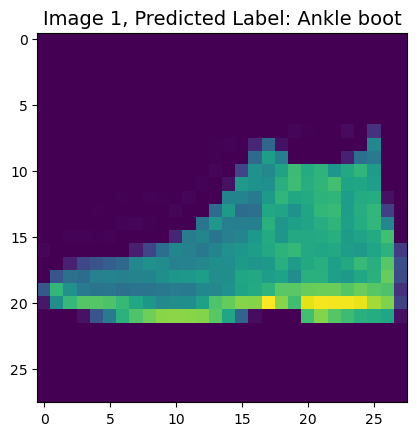

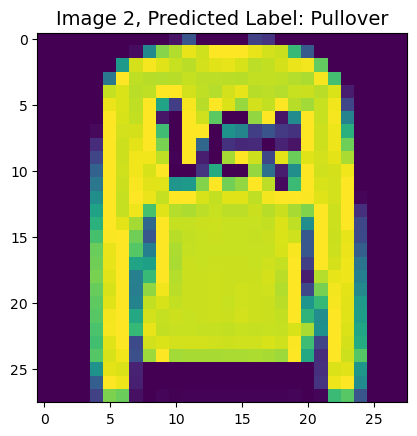

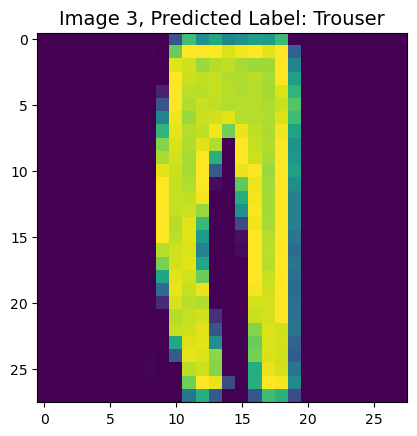

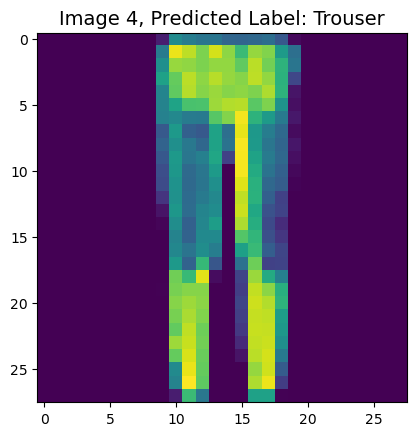

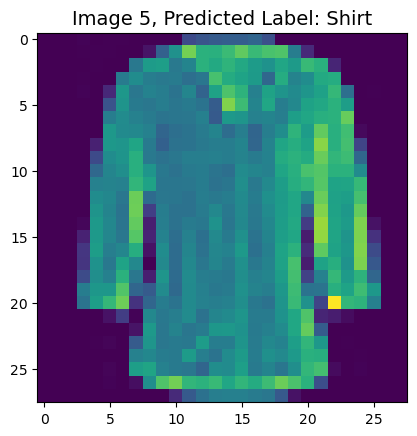

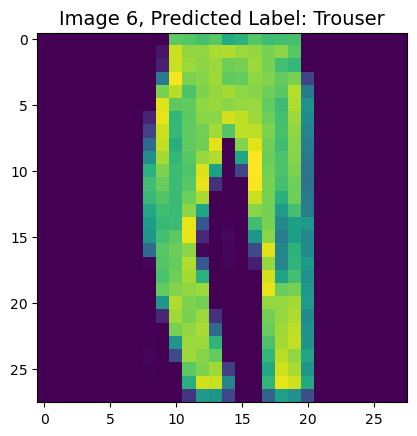

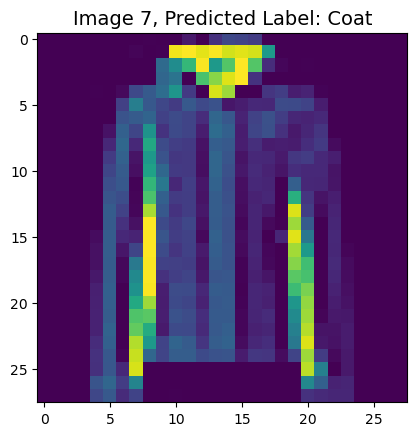

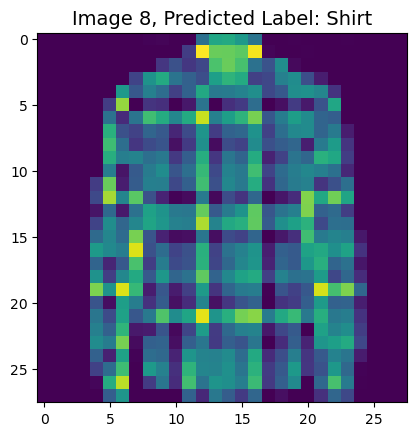

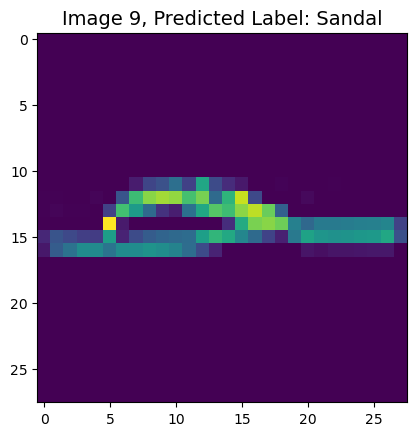

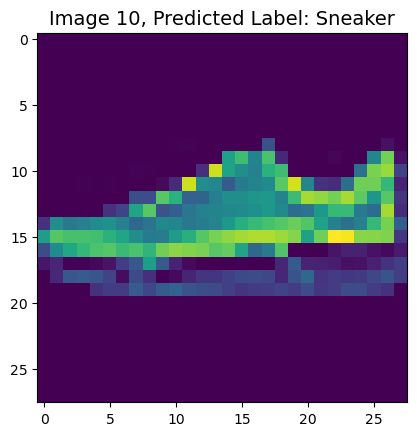

# Pre-trained models and transfer learning

Training CNNs can take a lot of time, and a lot of data is required for that task. However, much of the time is spent to learn the best low-level filters that a network is using to extract patterns from images. A natural question arises - can we use a neural network trained on one dataset and adapt it to classifying different images without full training process?

This approach is called **transfer learning**, because we transfer some knowledge from one neural network model to another. In transfer learning, we typically start with a pre-trained model, which has been trained on some large image dataset, such as **ImageNet**. Those models can already do a good job extracting different features from generic images, and in many cases just building a classifier on top of those extracted features can yield a good result.

In [ ]:
model = tf.keras.applications.ResNet50(weights="imagenet")

**Warning**: The expression `load_sample_images()["images"]` returns a Python list of images. However, in the latest versions, Keras does not accept Python lists anymore, so we must convert this list to a tensor. We can do this using `tf.constant()`, but here I have used `K.constant()` instead: it simply calls `tf.constant()` if you are using TensorFlow as the backend (as is the case here), but if you ever decide to use JAX or PyTorch as the backend instead, `K.constant()` will call the appropriate function from the chosen backend.

In [ ]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
import os
from tfcv import *

## Cats vs. Dogs Dataset

In this unit, we will solve a real-life problem of classifying images of cats and dogs. For this reason, we will use [Kaggle Cats vs. Dogs Dataset](https://www.kaggle.com/c/dogs-vs-cats), which can also be downloaded [from Microsoft](https://www.microsoft.com/en-us/download/details.aspx?id=54765&WT.mc_id=academic-77998-cacaste).

Let's download this dataset and extract it into `data` directory (this process may take some time!):

In [ ]:
#if not os.path.exists('data/kagglecatsanddogs_5340.zip'):
#    !wget -P data https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip

In [ ]:
import zipfile
if not os.path.exists('datasets/PetImages'):
    with zipfile.ZipFile('datasets/kagglecatsanddogs_5340.zip', 'r') as zip_ref:
        zip_ref.extractall('data')

In [ ]:
check_image_dir('data/PetImages/Cat/*.jpg')
check_image_dir('data/PetImages/Dog/*.jpg')

## Loading the Dataset

In previous examples, we were loading datasets that are built into Keras. Now we are about to deal with our own dataset, which we need to load from a directory of images.

In real life, the size of image datasets can be pretty large, and one cannot rely on all data being able to fit into memory. Thus, datasets are often represented as **generators** that can return data in minibatches suitable for training.

To deal with image classification, Keras includes special function `image_dataset_from_directory`, which can load images from subdirectories corresponding to different classes. This function also takes care of scaling images, and it can also split dataset into train and test subsets:

It is important to set the same `seed` value for both calls, because it affects the split of images between train and test dataset.

Dataset automatically picks up class names from directories, and you can access them if needed by calling:

> **Note**: All images in the dataset are represented as floatint point tensors with range 0-255. Before passing them to the neural network, we need to scale those values into 0-1 range. When plotting images, we either need to do the same, or convert values to the `int` type (which we do in the code above), in order to show `matplotlib` that we want to plot the original unscaled image.

Pre-trained models
For many image classification tasks one can find pre-trained neural network models. Many of those models are available inside keras.applications namespace, and even more models can be found on the Internet. Let's see how simplest VGG-16 model can be loaded and used:



There are a couple of important things here:
* Before passing an input to any pre-trained network it has to be pre-processed in a certain way. This is done by calling corresponding `preprocess_input` function, which receives a batch of images, and returns their processed form. In the case of VGG-16, images are normalized, and some pre-defined avarage value for each channels is subtracted. That is because VGG-16 was originally trained with this pre-processing.
* Neural network is applied to the input batch, and we receive as the result a batch of 1000-element tensors that show probability of each class. We can find the most probable class number by calling `argmax` on this tensor.
* Obtained result is a [number of an `ImageNet` class](https://gist.github.com/yrevar/942d3a0ac09ec9e5eb3a). To make sense of this result, we can also use `decode_predictions` function, that returns top n classes together with their names.

In [ ]:
Let's also see the architecture of the VGG-16 network:

In [ ]:
vgg.summary()

## GPU computations

Deep neural networks, such as VGG-16 and other more modern architectures require quite a lot of computational power to run. It makes sense to use GPU acceleration, if it is available. Luckily, Keras automatically speeds up the computatons on the GPU if it is available. We can check if Tensorflow is able to use GPU using the following code:

In [ ]:
tf.config.list_physical_devices('GPU')


## Extracting VGG features

If we want to use VGG-16 to extract features from our images, we need the model without final classification layers. We can instantiate VGG-16 model without top layers using this code:

The dimension of feature tensor is 7x7x512, but in order to visualize it we had to reshape it to 2D form.

Now let's try to see if those features can be used to classify images. Let's manually take some portion of images (50 minibatches, in our case), and pre-compute their feature vectors. We can use Tensorflow **dataset** API to do that. `map` function takes a dataset and applies a given lambda-function to transform it. We use this mechanism to construct new datasets, `ds_features_train` and `ds_features_test`, that contain VGG-extracted features instead of original images.

We used construction `.take(50)` to limit the dataset size, to speed up our demonstration. You can of course perform this experiment on the full dataset.

Now that we have a dataset with extracted features, we can train a simple dense classifier to distinguish between cats and dogs. This network will take feature vector of shape (7,7,512), and produce one output that corresponds either to a dog or to a cat. Because it is a binary classification, we use `sigmoid` activation function and `binary_crossentropy` loss.

The result is great, we can distinguish between a cat and a dog with almost 95% probability! However, we have only tested this approach on a  subset of all images, because manual feature extraction seems to take a lot of time.

## Transfer learning using one VGG network

We can also avoid manually pre-computing the features by using the original VGG-16 network as a whole during training, by adding feature extractor to our network as a first layer.

The beauty of Keras architecture is that VGG-16 model that we have defined above can also be used as a layer in another neural network! We just need to construct a network with dense classifier on top of it, and then train the whole network using back propagation.

This model looks like and end-to-end classification network, which takes an image and returns the class. However, the tricky thing is that we want VGG16 to act as a feature extractor, and not to be re-trained. Thus, we need to **freeze weights of convolutional feature extractor**. We can access first layer of the network by calling `model.layers[0]`, and we just need to set `trainable` property to `False`.

> **Note**: Freezing of feature extractor weights is needed, because otherwise untrained classifier layer can destroy the original pre-trained weights of convolutional extractor.

You can notice that while the total number of parameters in our network is around 15 million, we are only training 25k parameters. All other parameters of top-level convolutional filters are pre-trained. That is good, because we are able to fine-tune smaller number of parameters with smaller number of examples.

We will now train our network and see how good we can get. Expect rather long running time, and do not worry if the execution seems frozen for some time.